In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/anvarnarz/tashkent-real-estate-2019/uybor.xlsx


In [2]:
import pandas as pd
df = pd.read_excel("/kaggle/input/datasets/anvarnarz/tashkent-real-estate-2019/uybor.xlsx")
df.head()

,address,district,rooms,size,level,max_levels,price,lat,lng
0,"город Ташкент, Yunusobod район, Юнусабад 8-й к...",Yunusobod,3,57.0,4,4,52000,41.371471,69.281049
1,"город Ташкент, Yakkasaroy район, 1-й тупик Шот...",Yakkasaroy,2,52.0,4,5,56000,41.291115,69.261104
2,"город Ташкент, Chilonzor район, Чиланзар 2-й к...",Chilonzor,2,42.0,4,4,37000,41.280784,69.223683
3,"город Ташкент, Chilonzor район, Чиланзар 9-й к...",Chilonzor,3,65.0,1,4,49500,41.290163,69.196862
4,"город Ташкент, Chilonzor район, площадь Актепа",Chilonzor,3,70.0,3,5,55000,41.300156,69.210831


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df.shape)
df.info()
print(df.isnull().sum())
print("Takroriy qatorlar:", df.duplicated().sum())
df.describe()

(7421, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7421 entries, 0 to 7420
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   address     7421 non-null   object 
 1   district    7421 non-null   object 
 2   rooms       7421 non-null   int64  
 3   size        7421 non-null   float64
 4   level       7421 non-null   int64  
 5   max_levels  7421 non-null   int64  
 6   price       7421 non-null   int64  
 7   lat         7421 non-null   float64
 8   lng         7421 non-null   float64
dtypes: float64(3), int64(4), object(2)
memory usage: 521.9+ KB
address       0
district      0
rooms         0
size          0
level         0
max_levels    0
price         0
lat           0
lng           0
dtype: int64
Takroriy qatorlar: 696


,rooms,size,level,max_levels,price,lat,lng
count,7421.000000,7421.000000,7421.000000,7421.000000,7421.000000,7421.000000,7421.000000
mean,2.619728,73.150726,3.699367,6.031397,59117.618919,41.303620,69.256615
std,1.076887,36.999670,2.239028,2.607673,46701.090308,0.033771,0.059061
min,1.000000,14.000000,1.000000,1.000000,10500.000000,41.186375,69.148915
25%,2.000000,50.000000,2.000000,4.000000,35000.000000,41.281265,69.205802
50%,3.000000,65.000000,3.000000,5.000000,46500.000000,41.296388,69.260189
75%,3.000000,85.000000,5.000000,9.000000,66847.000000,41.324956,69.293713
max,10.000000,456.000000,19.000000,25.000000,800000.000000,41.424522,69.588687


In [4]:
df = df.drop_duplicates().dropna(subset=["price", "size", "rooms", "district"])

# Eng yuqori va eng past 1% ni kesib tashlaymiz
for col in ["price", "size"]:
    low, high = df[col].quantile([0.01, 0.99])
    df = df[(df[col] >= low) & (df[col] <= high)]

df["price_per_m2"] = df["price"] / df["size"]
print(df.shape)

(6479, 10)


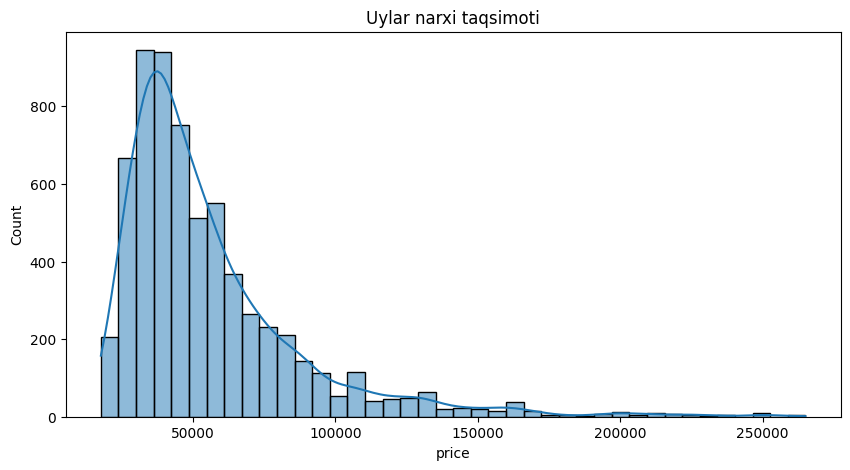

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df["price"], bins=40, kde=True)
plt.title("Uylar narxi taqsimoti")
plt.show()

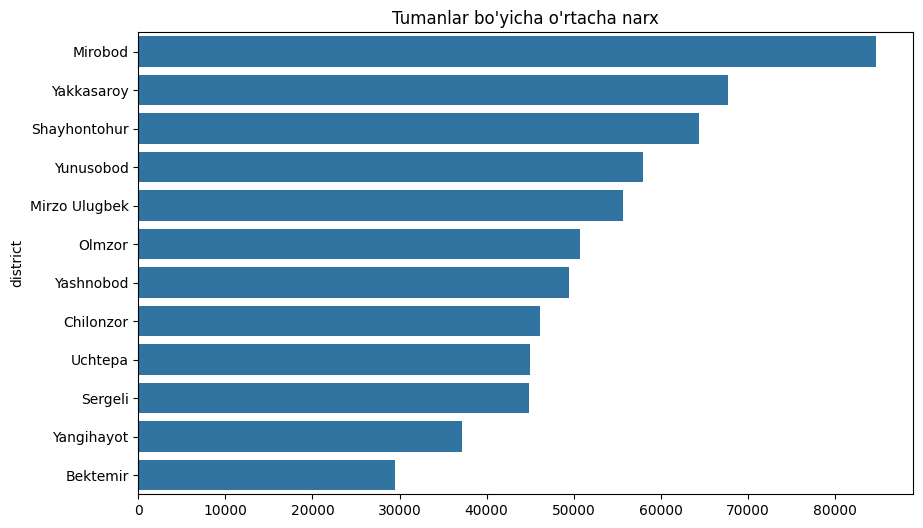

In [6]:
district_price = df.groupby("district")["price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=district_price.values, y=district_price.index)
plt.title("Tumanlar bo'yicha o'rtacha narx")
plt.show()

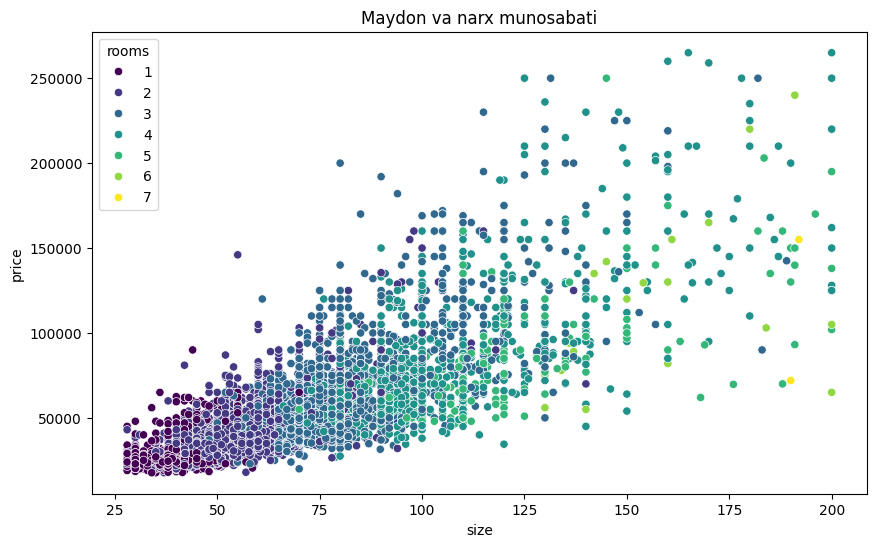

In [7]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="size", y="price", hue="rooms", palette="viridis")
plt.title("Maydon va narx munosabati")
plt.show()

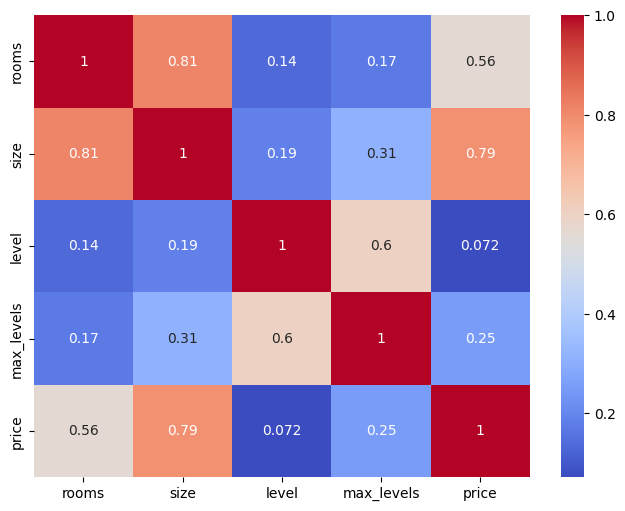

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[["rooms", "size", "level", "max_levels", "price"]].corr(), annot=True, cmap="coolwarm")
plt.show()

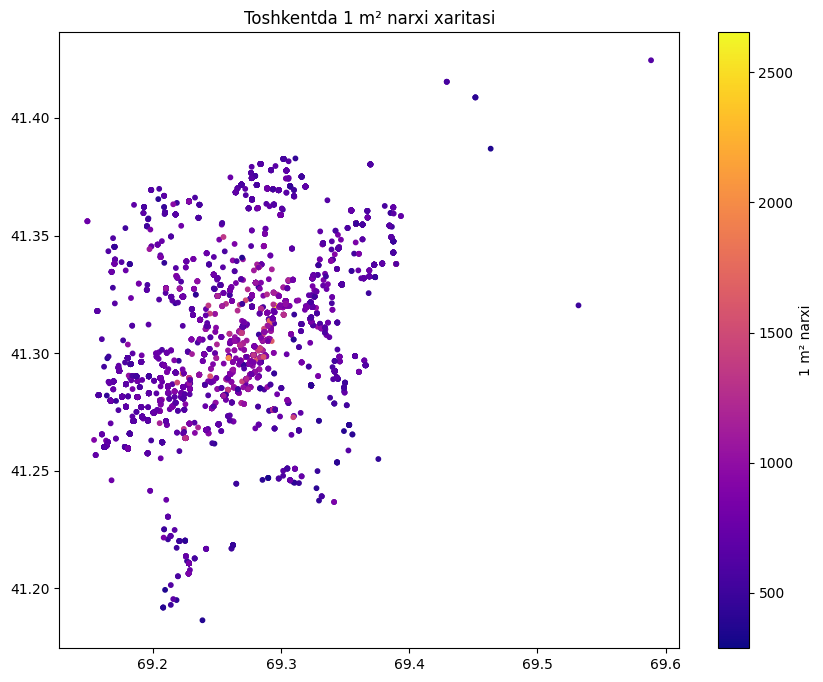

In [9]:
plt.figure(figsize=(10, 8))
sc = plt.scatter(df["lng"], df["lat"], c=df["price_per_m2"], cmap="plasma", s=10)
plt.colorbar(sc, label="1 m² narxi")
plt.title("Toshkentda 1 m² narxi xaritasi")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

X = df[["rooms", "size", "level", "max_levels"]]
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
print("R2:", r2_score(y_test, model.predict(X_test)))

R2: 0.648579333624859


In [11]:
print(district_price.round(0).head(3))
print(district_price.round(0).tail(3))
print(df[["rooms", "size", "level", "max_levels", "price"]].corr()["price"].round(2))
print("O'rtacha 1 m2 narxi:", round(df["price_per_m2"].mean(), 1))
print("Medianali narx:", df["price"].median())

district
Mirobod         84756.0
Yakkasaroy      67722.0
Shayhontohur    64405.0
Name: price, dtype: float64
district
Sergeli       44843.0
Yangihayot    37192.0
Bektemir      29462.0
Name: price, dtype: float64
rooms         0.56
size          0.79
level         0.07
max_levels    0.25
price         1.00
Name: price, dtype: float64
O'rtacha 1 m2 narxi: 775.5
Medianali narx: 46500.0


## Xulosalar

1. **Narx taqsimoti:** narxlar o'ng tomonga cho'zilgan. Ko'pchilik uylar arzon va o'rta segmentda, kam sonli uylar juda qimmat. Butun uyning mediana narxi 46 500, 1 m² ning o'rtacha narxi esa taxminan 775.
2. **Tumanlar:** eng qimmat tumanlar **Mirobod** (o'rtacha 84 756), **Yakkasaroy** (67 722) va **Shayxontohur** (64 405). Eng arzon tumanlar **Bektemir** (29 462), **Yangihayot** (37 192) va **Sergeli** (44 843). Mirobod Bektemirdan taxminan 2.9 baravar qimmat.
3. **Omillar:** narx bilan eng kuchli bog'liqlik **maydonda** (korrelyatsiya 0.79), keyin **xonalar soni** (0.56) va uy qavatliligi (0.25). Uy qavati (0.07) deyarli ta'sir qilmaydi.
4. **Xarita:** 1 m² narxi joylashuvga qarab farq qiladi, markaziy hududlarda yuqori.
5. **Model:** chiziqli regressiya R² = 0.65 natija berdi, ya'ni narx o'zgarishining taxminan 65% ini tushuntiradi. Tuman va koordinatalarni qo'shsak, aniqlik oshishi mumkin.
6. **Cheklov:** ma'lumotlar 2019 yilga tegishli va uybor.uz e'lonlaridan olingan, shuning uchun hozirgi bozor narxlarini to'liq aks ettirmaydi.
7. **Keyingi qadam:** `district` ustunini modelga qo'shib, aniqlikni oshirish mumkin.